# FlowDataLab · AWARE Prioritisation Challenge — notebook destilado

**Qué es:** el resumen de todo el proyecto en un solo sitio: qué dicen los datos, de dónde sale la nota, por qué unos modelos
funcionan y otros no, dónde está el techo y por qué elegimos las entregas que elegimos. El detalle de cada prueba vive en
`futuro/LGB_futuro.ipynb` (diario de la línea con futuro), `notebooks/01_eda.ipynb` (EDA), `notebooks/LGB_adri.ipynb` y
`notebooks/NN_pablo.ipynb` (línea limpia), `realista/` (línea sin futuro) y `futuro/pruebas/resultados.jsonl` (registro de ejecuciones).

**Cómo se ejecuta:** de arriba abajo, en unos 2–3 minutos. No entrena nada: calcula lo barato desde los datos (`Data/`), los OOF
(`oof/`, `futuro/oof`, `futuro/pruebas/oof`, `realista/oof`) y los envíos; lo caro lo lee de los registros. Si falta un archivo,
usa la cifra registrada y lo indica con `(registro)`.

**Vocabulario.** *Snapshot* = una muestra (`sample_id`): la lista de tareas abiertas del controlador en un instante (9–59, ~36).
*Racha* = snapshots seguidos de la misma sesión sin huecos de más de 4.5 s. *Tramo* = racha × tarea correcta.
*CV* = top-3 hit rate fuera de fold con `Data/folds.csv` (5 folds, agrupados por controlador: cada controlador se predice con un
modelo que no lo ha visto). *Público* = controlador 020 (2 sesiones); *privado*, el que decide = controlador 023 (3 sesiones).

## 0 · Las técnicas, explicadas desde cero

Esta sección no supone ningún conocimiento previo. Cada técnica que aparece en el resto del notebook se explica aquí.

### 0a · El problema como *ranking*
En cada snapshot hay una lista de ~36 tareas y hay que **ordenarlas** de más a menos probable. No es una clasificación "sí/no" fila a
fila: lo que importa es la posición de la tarea correcta *dentro de su lista*. Por eso la métrica es el **top-3 hit rate**: la
fracción de snapshots en los que la tarea correcta queda entre las 3 primeras. Si se eligen 3 tareas al azar, se acierta ~9 % de las
veces (3 de ~36).

### 0b · Validación cruzada por controlador, OOF y CV anidada
- **Validación cruzada (CV):** se parte el conjunto etiquetado en 5 grupos (*folds*); se entrena con 4 y se mide en el 5.º, cinco
  veces. Así cada snapshot se predice con un modelo que no lo vio.
- **Por controlador (GroupKFold, `Data/folds.csv`):** todos los snapshots de un mismo controlador caen en el mismo fold. El test es de
  controladores nuevos (020 y 023), así que la CV debe medir lo mismo: acertar con un controlador que el modelo nunca ha visto. Si se
  repartieran los snapshots al azar, el modelo vería al mismo controlador en entrenamiento y la nota saldría inflada.
- **OOF (*out-of-fold*):** la predicción de cada snapshot hecha por el modelo del fold que no lo vio. Con los OOF de todos los modelos
  se pueden comparar y combinar sin hacer trampa.
- **CV anidada:** cuando además hay que *elegir* algo (un peso, un parámetro del suavizado), se elige con 4 folds y se mide en el 5.º.
  Elegirlo mirando todo el OOF da una cifra optimista.

### 0c · De un árbol de decisión a LightGBM LambdaRank
- **Árbol de decisión:** una secuencia de preguntas sobre las columnas ("¿llega una instrucción al avión en menos de 10 s?",
  "¿es un transfer?") que termina en una puntuación. Una pregunta parte los datos en dos; cada final del camino es una **hoja**.
- **Gradient boosting:** en vez de un árbol grande, cientos de árboles pequeños en serie; cada uno corrige lo que los anteriores aún
  hacen mal. La puntuación final es la suma de todos.
- **LightGBM:** una implementación rápida de gradient boosting. Maneja de forma nativa las celdas vacías (aquí significan "no
  aplica") y las categorías como `task_index`.
- **LambdaRank:** el objetivo de entrenamiento. En lugar de "acierta la etiqueta de cada fila", optimiza directamente el orden dentro
  de cada snapshot, dando más peso a lo que pasa en las primeras posiciones (`lambdarank_truncation_level`).
- **Hojas (`num_leaves`) y `min_child_samples`:** cuántas preguntas puede encadenar cada árbol y cuántos ejemplos debe tener como
  mínimo cada hoja. 63 hojas y 100 de mínimo = árboles más expresivos pero sin hojas diminutas.
- **`extra_trees`:** en cada pregunta, el corte se elige al azar entre unos pocos candidatos en vez del mejor exacto. Los árboles
  salen más distintos entre sí y el conjunto generaliza mejor a controladores nuevos.
- **Semillas:** el entrenamiento tiene partes aleatorias; entrenar con varias semillas y promediar reduce ese ruido (±0.2 puntos de CV
  con 3 semillas; casi nada a partir de ~20).

### 0d · Probabilidades dentro del snapshot y el segundo paso de sesión
- **Softmax:** convierte las puntuaciones de las tareas de un snapshot en probabilidades que suman 1: p(i) = exp(s_i) / Σ exp(s_j).
  El log-softmax es su logaritmo.
- **Logit condicional:** un modelo lineal pequeño cuya salida pasa por un softmax dentro del snapshot. Es el **segundo paso de
  sesión** (`futuro/feat_session.py`): toma el score del primer modelo y 9 variables calculadas sobre *toda la sesión* (por ejemplo,
  la probabilidad máxima que esa misma tarea tuvo en otras rachas) y aprende 9 pesos. Al ser tan pequeño no sobreajusta.
- **Suavizado en la racha:** se promedia la probabilidad de cada tarea con la de la misma tarea en los snapshots vecinos de la racha,
  con pesos que decaen con la distancia.

### 0e · Combinar modelos
- **Mezcla:** media de las probabilidades (o de los log-softmax) de dos modelos con un peso w elegido por CV anidada. M30 =
  0.7 · C + 0.3 · N, en probabilidades: si un modelo da ~0 a una tarea, el otro aún puede salvarla (en log, un ~0 la veta).
- **Stack:** un segundo modelo que aprende a combinar los OOF de varios. Solo ayuda si los modelos fallan en sitios distintos.

### 0f · El oráculo
Variables que dicen qué hicieron **otros controladores** en el mismo escenario y el mismo momento (todas las sesiones de un escenario
tienen los mismos aviones): por ejemplo, en qué fracción de las otras sesiones esta tarea llegó a trabajarse. Usa etiquetas de otras
sesiones, así que se calcula **por fold**: para predecir un fold solo se usan sesiones de los otros folds y de otros controladores.

### 0g · Cómo se mide si algo mejora
- **SHAP:** reparte la puntuación de cada predicción entre las variables que la produjeron; sumado por familias dice de dónde viene
  la información.
- **Bootstrap por controladores:** se re-muestrean los 18 controladores con reemplazo muchas veces y se recalcula la ganancia media;
  da un intervalo de confianza que tiene en cuenta que unos controladores ganan y otros pierden.
- **La nota que cuenta:** se elige **una** entrega y la clasificación final es solo su nota en el **privado** (controlador 023, el 51 %
  de las filas de test; el público, 020, es el otro 49 % y solo sirve de orientación). El privado se estima con la sección 6b.

### 0h · Las familias de variables
| Familia | Prefijo | Qué mide | Ejemplo | Usa |
|---|---|---|---|---|
| base | (originales) | lo que trae el dataset: tipo de tarea, tiempos al borde del sector, estado del avión, rangos `l_*` | `time_to_sector`, `k_timeToExitPoint` | solo el snapshot |
| logic | `logic_*` | reglas escritas a mano: plazo por tipo, si la tarea es factible ahora, orden de urgencia | `logic_window_dist` | solo el snapshot |
| past | `p_*`, `blk_*`, `gap_*` | cuánto lleva la tarea en la lista, qué cambió desde el snapshot anterior, posición en la racha | `p_task_start` | snapshots pasados |
| future | `f_*` | segundos hasta la siguiente instrucción al avión y su tipo; cuándo desaparece la tarea de la lista | `f_next_input`, `f_task_end` | snapshots futuros |
| clear | `sx_*` | segundos hasta que cambia el nivel autorizado, el rumbo, la zona, el conflicto o la ruta del avión | `sx_task` | snapshots futuros |
| instr | `si_*` | segundos hasta la siguiente instrucción **de cada tipo** y hasta la que **encaja** con la tarea | `si_match` | snapshots futuros |
| oráculo | `or_*` | qué hicieron otros controladores con esa tarea en el mismo escenario | `or_ever`, `or_near180` | otras sesiones |

### 0i · Cómo se organiza el entrenamiento: folds fijos, semillas variables
- **Los folds son fijos.** `Data/folds.csv` lo genera `src/folds.py` de forma determinista (sin semillas): los 18 controladores, de
  mayor a menor nº de snapshots, se asignan uno a uno al fold que menos snapshots lleva. Cada controlador (y por tanto cada sesión)
  cae entero en un fold. Todo el equipo usa el mismo archivo, así que **todas las cifras del proyecto son comparables entre sí**:
  si dos modelos difieren, no es porque se partieran los datos de otra forma.
- **El azar está dentro del modelo.** LightGBM toma en cada árbol el 80 % de las filas (`subsample`) y el 70 % de las columnas
  (`colsample_bytree`); con `extra_trees` además elige los cortes al azar. Una **semilla** fija ese azar: con la misma semilla, el
  mismo modelo; con otra, un modelo algo distinto.
- **Se promedian semillas.** Cada fold se entrena con k semillas (0, 1, …, k−1) y se promedian sus puntuaciones; el modelo de test se
  entrena con todos los datos etiquetados y las mismas k semillas. Más semillas = menos ruido, con rendimientos decrecientes (3 → 10 →
  20–30; a partir de ~20 ya no cambia nada).
- **Consecuencia práctica:** dos variantes solo se comparan con **las mismas semillas**; y una diferencia de CV menor que el ruido
  entre grupos de semillas no significa nada. La sección 2b mide ese ruido.

In [1]:
import sys, os, json, numpy as np, pandas as pd
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "Data").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "cv"), str(ROOT / "futuro"), str(ROOT / "futuro" / "pruebas")]
from metric import hits
from base_fut import datos
pd.set_option("display.width", 200, "display.max_colwidth", 80)

lab, te, fs = datos()          # train+validation y test con las features de futuro (cache en futuro/pruebas/cache.parquet)
TY = ['entry_conflict_resolution', 'exit_conflict_resolution', 'entry_coordination', 'exit_coordination',
      'assume_aircraft', 'transfer_aircraft', 'conflict_resolution', 'non_conformance_resolution', 'qos_improvement',
      'entry_conditions', 'exit_conditions', 'aircraft_request', 'zone_conflict', 'return_to_route']
snap = lab.drop_duplicates("sample_id").set_index("sample_id")[["session", "scenario", "atco", "fold", "seq_len", "block"]]
resp = lab[lab.target_index == 1].set_index("sample_id")

def oof(nombre, carpeta="oof"):
    for d in ("oof", "futuro/oof", "futuro/pruebas/oof", "realista/oof") if carpeta == "oof" else \
             ("preds", "futuro/preds", "futuro/pruebas/preds", "realista/preds"):
        for base in (ROOT, Path.home() / "FlowDataLab_archivo"):     # el archivo guarda salidas que ya no están en el repo
            p = base / d / f"{nombre}.csv"
            if p.exists():
                return pd.read_csv(p)
    return None

def registro(nombre):
    for f in (ROOT / "futuro/pruebas/resultados.jsonl", ROOT / "pruebas/resultados.jsonl"):
        for l in open(f):
            x = json.loads(l)
            if x["nombre"] == nombre:
                r = x
    return locals().get("r")

def medir(nombre):
    o = oof(nombre)
    if o is None:
        r = registro(nombre)
        return dict(cv=r and r["cv"], peor_controlador=r and r["min_atco"], mediana_sesion=None, fuente="(registro)")
    h = hits(o).rename("hit").to_frame().join(snap)
    return dict(cv=round(h.hit.mean(), 4), peor_controlador=round(h.groupby("atco").hit.mean().min(), 3),
                mediana_sesion=round(h.groupby("session").hit.median().median() if False else h.groupby("session").hit.mean().median(), 4),
                fuente="OOF")
print(f"{lab.sample_id.nunique()} snapshots etiquetados, {te.sample_id.nunique()} de test")

13175 snapshots etiquetados, 1863 de test


## 1 · Los datos

Cada fila es una tarea del snapshot; exactamente una tiene `target_index = 1`. Train + validation: 18 controladores,
37 sesiones, 3 escenarios de tráfico (todas las sesiones de un escenario tienen los mismos aviones). Test: 020 y 023.

In [2]:
est = pd.DataFrame({
    "snapshots": [lab.sample_id.nunique(), te.sample_id.nunique()],
    "filas": [len(lab), len(te)],
    "sesiones": [lab.session.nunique(), te.session.nunique()],
    "controladores": [lab.atco.nunique(), te.atco.nunique()],
    "tareas por snapshot (media)": [round(lab.groupby("sample_id").size().mean(), 1), round(te.groupby("sample_id").size().mean(), 1)],
}, index=["etiquetado", "test"])
est

,snapshots,filas,sesiones,controladores,tareas por snapshot (media)
etiquetado,13175,474688,37,18,36.0
test,1863,66409,5,2,35.6


### 1a · Qué tipos de tarea se eligen: el *lift*

Lift = % de las respuestas / % de las filas. Transfer y assume son pocas filas y muchas respuestas; las coordinaciones
(entry/exit) son muchas filas y pocas respuestas: casi siempre hay alguna en la lista y casi nunca es la que se trabaja.

In [3]:
filas = lab.task_index.value_counts(normalize=True)
resps = resp.task_index.value_counts(normalize=True)
lift = pd.DataFrame({"% filas": filas * 100, "% respuestas": resps * 100}).fillna(0)
lift["lift"] = lift["% respuestas"] / lift["% filas"]
lift.index = [TY[i] for i in lift.index]
lift.sort_values("% respuestas", ascending=False).round(2)

,% filas,% respuestas,lift
transfer_aircraft,6.37,26.77,4.20
assume_aircraft,16.62,25.55,1.54
zone_conflict,11.19,16.10,1.44
entry_coordination,29.82,8.11,0.27
return_to_route,3.48,7.11,2.04
exit_coordination,12.68,5.65,0.45
exit_conditions,7.72,3.40,0.44
conflict_resolution,2.33,2.96,1.27
qos_improvement,6.30,1.95,0.31
exit_conflict_resolution,1.28,1.50,1.17


### 1b · La estructura de las etiquetas

Dos regularidades que no son de un snapshot sino de la sesión, y que explican buena parte del modelo final:
1. **Dentro de una racha el controlador sigue con la misma tarea.** Tras un hueco, casi nunca vuelve a ella.
2. **Cada tarea se trabaja en un solo episodio de la sesión.**

In [4]:
s = snap.join(resp[["task_name", "t"]]).sort_values(["session", "t"])
s["prev_task"] = s.groupby("session").task_name.shift()
s["prev_block"] = s.groupby("session").block.shift()
dentro = s[s.block == s.prev_block]
tras_hueco = s[(s.block != s.prev_block) & s.prev_block.notna()]
ep = s.groupby(["session", "task_name"]).block.nunique()
pd.Series({
    "repite la respuesta del snapshot anterior, dentro de la racha": f"{(dentro.task_name == dentro.prev_task).mean():.1%}",
    "repite la respuesta tras un hueco entre rachas": f"{(tras_hueco.task_name == tras_hueco.prev_task).mean():.1%}",
    "tareas que son respuesta en una sola racha de la sesión": f"{(ep == 1).mean():.1%}",
    "snapshots por racha (media)": f"{snap.groupby('block').size().mean():.1f}",
}).to_frame("valor")

,valor
"repite la respuesta del snapshot anterior, dentro de la racha",94.8%
repite la respuesta tras un hueco entre rachas,0.2%
tareas que son respuesta en una sola racha de la sesión,98.4%
snapshots por racha (media),4.2


### 1c · Lo que distingue a la tarea elegida (dentro del propio snapshot)

Del EDA (`notebooks/01_eda.ipynb`, sección 5–6), estable en los 5 folds:
- La elegida está **más cerca del borde del sector** (`time_to_sector`, `k_timeToExitPoint`, rango `l_rank_absf1_*`): assume justo
  antes de entrar, transfer justo antes de salir. Es la más cercana dentro de su tipo el 70–76 % de las veces (transfer).
- Tiene **menos vacíos**: los `k_*` están vacíos cuando el avión no está asumido (los vacíos significan "no aplica").
- Un ranker de una sola columna (prior por tipo + rango de cercanía al borde) ya da **0.41**; el azar da 0.09.
- **Twin** assume + entry_coordination del mismo avión: el 29.9 % de las respuestas; se elige assume el 68–78 %.
- El **escenario** pesa más que el controlador en el tipo elegido (Cramér's V 0.159 frente a 0.096).

In [5]:
# comprobación rápida: la elegida es la más cercana al borde dentro de su tipo
x = lab[lab.task_index.isin([4, 5])].copy()
x["rk"] = x.assign(a=x.time_to_sector.abs()).groupby(["sample_id", "task_index"]).a.rank(method="first")
r = x[x.target_index == 1].groupby("task_index").rk.apply(lambda v: (v == 1).mean())
r.index = [TY[i] for i in r.index]
r.rename("P(la elegida es la más cercana al borde de su tipo)").round(3).to_frame()

,P(la elegida es la más cercana al borde de su tipo)
assume_aircraft,0.684
transfer_aircraft,0.724


## 1d · Relaciones entre variables

Cuatro miradas a cómo se relacionan las variables entre sí y con la tarea elegida. Todas se calculan aquí (unos segundos) sobre los
datos etiquetados, sin modelos.

**Cómo leer "AUC dentro del snapshot":** para una variable, la probabilidad de que la tarea elegida tenga un valor más extremo que
otra tarea cualquiera *del mismo snapshot*, en el sentido que mejor separa. 0.5 = no separa nada; 1 = la variable sola ordena la lista
perfectamente. Se calcula dentro del snapshot porque es lo único que importa para el ranking.

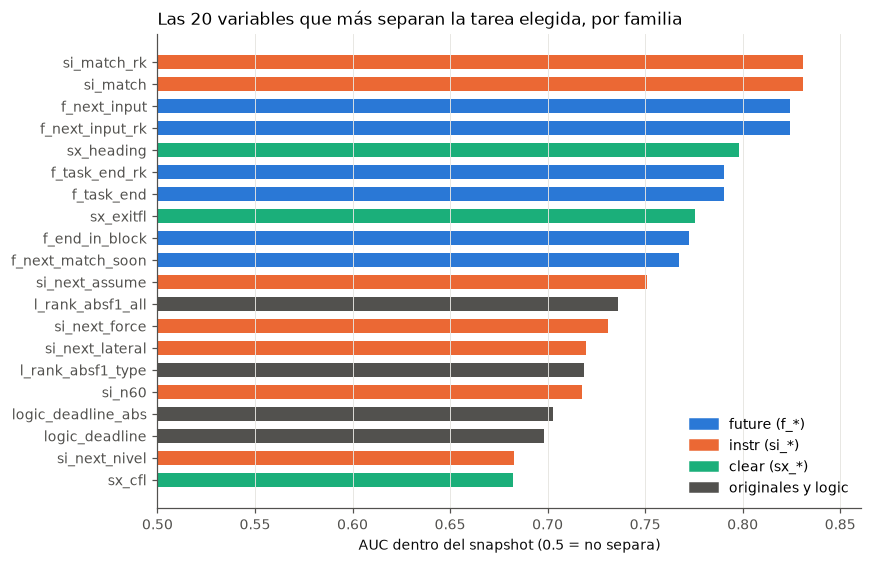

,max,median,size
familia,,,
instr,0.831,0.639,18
future,0.824,0.714,12
clear,0.798,0.641,10
base,0.736,0.542,87
logic,0.703,0.615,14
past,0.609,0.515,11


In [6]:
import matplotlib.pyplot as plt
from f10_instr import datos_instr
labI, teI, fsI = datos_instr()                       # añade el bloque instr (si_*) con su caché
FAM = {"base": [c for c in fsI["base"] if c != "task_index"], "logic": fsI["logic"], "past": fsI["past"],
       "future": fsI["future"], "clear": fsI["clear"], "instr": fsI["instr"]}
CAT, GRIS = ["#2a78d6", "#eb6834", "#1baf7a"], "#52514e"     # paleta de referencia (3 primeras posiciones) y texto secundario
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
                     "axes.labelcolor": "#0b0b0b", "xtick.color": GRIS, "ytick.color": GRIS, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "font.size": 9})

# AUC dentro del snapshot de cada variable: percentil de la elegida en su lista (0.5 = no separa)
cols = list(dict.fromkeys(c for f in FAM.values() for c in f))
FAM = {k: [c for c in v if c in cols] for k, v in FAM.items()}
R = labI[["sample_id"] + cols].copy()
pct = R.groupby("sample_id")[cols].rank(pct=True, method="average")
auc = pct[labI.target_index.values == 1].mean()
auc = pd.DataFrame({"auc": np.maximum(auc, 1 - auc), "sentido": np.where(auc >= 0.5, "más alto", "más bajo"),
                    "familia": [next(k for k, v in FAM.items() if c in v) for c in auc.index]})
top = auc.sort_values("auc", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 5.2))
from matplotlib.patches import Patch
grupo_fam = {"future": "future (f_*)", "instr": "instr (si_*)", "clear": "clear (sx_*)"}
gcol = {"future (f_*)": CAT[0], "instr (si_*)": CAT[1], "clear (sx_*)": CAT[2], "originales y logic": GRIS}
g = [grupo_fam.get(f, "originales y logic") for f in top.familia]
ax.barh(top.index[::-1], top.auc[::-1] - 0.5, left=0.5, color=[gcol[x] for x in g][::-1], height=0.62)
ax.set_xlim(0.5, top.auc.max() + 0.03); ax.set_xlabel("AUC dentro del snapshot (0.5 = no separa)")
ax.set_title("Las 20 variables que más separan la tarea elegida, por familia", loc="left")
ax.legend(handles=[Patch(color=c, label=k) for k, c in gcol.items()], frameon=False, loc="lower right")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
auc.groupby("familia").auc.agg(["max", "median", "size"]).sort_values("max", ascending=False).round(3)

**Lectura:** las variables del **futuro** e `instr` dominan: saber cuándo llega la siguiente instrucción (compatible) al avión o
cuándo desaparece la tarea separa la elegida casi por sí solo. De las originales, las que miden **cercanía al borde del sector** son
las mejores. `clear` también separa mucho por sí sola (cambio de rumbo, `sx_heading`, 0.80); `logic` algo menos y `past` casi nada
(AUC máximo 0.61).

### Correlación entre familias
Media del |Spearman| entre las variables de cada par de familias (muestra de 60 000 filas). Alta = las dos familias cuentan en parte
lo mismo.

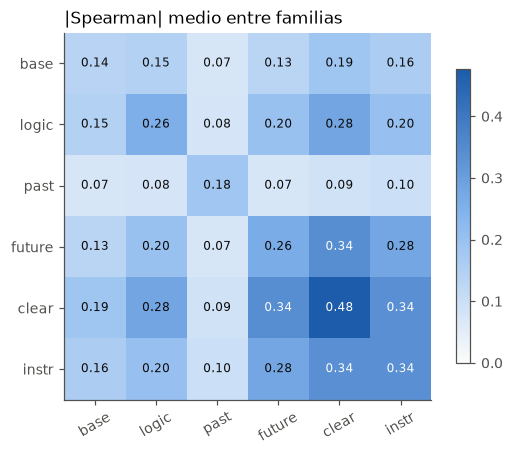

In [7]:
mu = labI.sample(60000, random_state=0)
rho = mu[cols].rank().corr().abs()
fam_of = {c: k for k, v in FAM.items() for c in v}
names = list(FAM)
def media_bloque(a, b):
    v = rho.loc[FAM[a], FAM[b]].values.astype(float)
    if a == b:
        v = v[~np.eye(v.shape[0], dtype=bool)]        # sin la diagonal (cada variable consigo misma)
    return np.nanmean(v)
Mf = pd.DataFrame([[media_bloque(a, b) for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(Mf.values, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#fcfcfb", "#86b6ef", "#1c5cab"]),
               vmin=0, vmax=max(0.4, Mf.values.max()))
ax.set_xticks(range(len(names)), names, rotation=30); ax.set_yticks(range(len(names)), names); ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{Mf.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="#0b0b0b" if Mf.values[i, j] < 0.3 else "#fcfcfb")
ax.set_title("|Spearman| medio entre familias", loc="left"); fig.colorbar(im, shrink=0.8); plt.tight_layout(); plt.show()

**Lectura:** future, instr y clear están relacionadas entre sí (0.28–0.34; las tres miran "qué le pasa al avión después"), pero no son copias:
cada una mide un evento distinto (cualquier instrucción, la que encaja con la tarea, un cambio de estado). `logic` se solapa sobre
todo con clear y future (0.20–0.28): sus plazos y factibilidades anticipan lo que esas familias miden directamente, y por eso con el
futuro presente deja de aportar. `past` va casi por libre (≤ 0.10), pero separa poco por sí sola (AUC máximo 0.61).

### Un *embedding* de las tareas
Cada tarea del snapshot es un punto en un espacio de ~170 variables. Un **embedding** lo proyecta a 2 dimensiones conservando qué
puntos están cerca. Se usa **t-SNE** (mantiene vecindades locales) sobre las variables estandarizadas *dentro del snapshot* (cada valor
menos la media de su lista), porque lo que decide es cómo es la tarea **respecto a las demás de su lista**. Muestra de 1 500 snapshots.

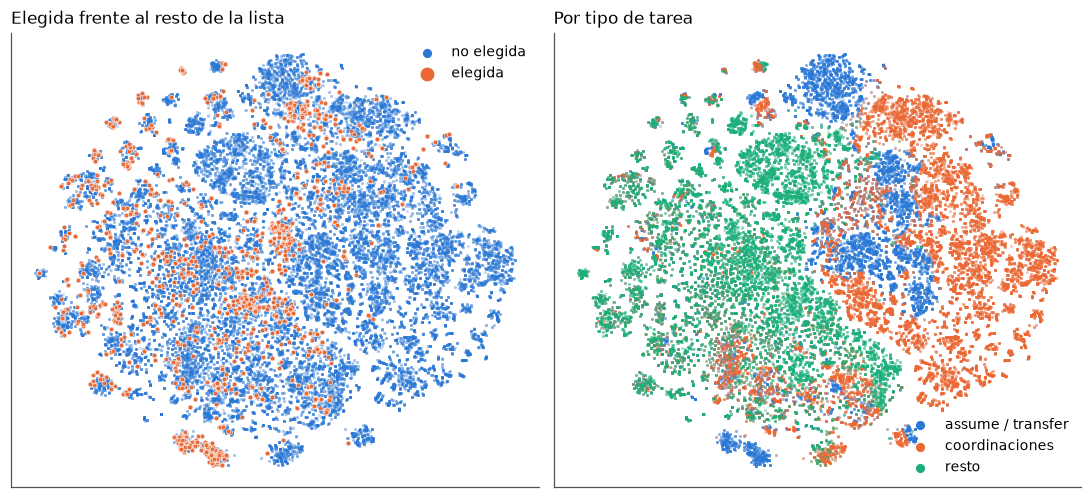

53629 tareas de 1500 snapshots; elegidas: 1500


In [8]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
ids = labI.sample_id.drop_duplicates().sample(1500, random_state=1)
S = labI[labI.sample_id.isin(ids)].copy()
X = S[cols].astype(float)
X = (X - X.groupby(S.sample_id.values).transform("mean")).fillna(0)
X = StandardScaler().fit_transform(X)
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=0).fit_transform(X)
grupo = np.select([S.task_index.isin([4, 5]), S.task_index.isin([2, 3])], ["assume / transfer", "coordinaciones"], "resto")
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))
el = S.target_index.values == 1
axs[0].scatter(*emb[~el].T, s=4, c=CAT[0], alpha=0.25, linewidths=0, label="no elegida")
axs[0].scatter(*emb[el].T, s=10, c=CAT[1], alpha=0.9, edgecolors="#fcfcfb", linewidths=0.4, label="elegida")
axs[0].set_title("Elegida frente al resto de la lista", loc="left")
for g, c in zip(["assume / transfer", "coordinaciones", "resto"], CAT):
    m = grupo == g
    axs[1].scatter(*emb[m].T, s=4, c=c, alpha=0.35, linewidths=0, label=g)
axs[1].set_title("Por tipo de tarea", loc="left")
for a in axs:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    leg = a.legend(frameon=False, markerscale=3, loc="best")
    for h in leg.legend_handles: h.set_alpha(1)
plt.tight_layout(); plt.show()
print(f"{len(S)} tareas de {S.sample_id.nunique()} snapshots; elegidas: {el.sum()}")

**Lectura:** las elegidas se agrupan en islas pequeñas y densas (tareas con instrucción inminente y cercanas al borde), sobre todo en
zonas de assume/transfer y del resto de tareas con acción. Las coordinaciones ocupan su propia región y en ella las elegidas son pocas
y están mezcladas con no elegidas casi iguales: con estas variables no se distinguen de sus vecinas. Es la imagen geométrica de por
qué las coordinaciones son el techo. (t-SNE conserva vecindades, no distancias: el tamaño y la separación de las islas no se interpretan.)

### Qué tipo gana cuando coinciden dos
Para cada par de tipos X, Y presentes a la vez en un snapshot cuya respuesta es uno de los dos: P(se elige X). Por encima de 0.5
(azul) gana el tipo de la fila; por debajo (rojo), el de la columna.

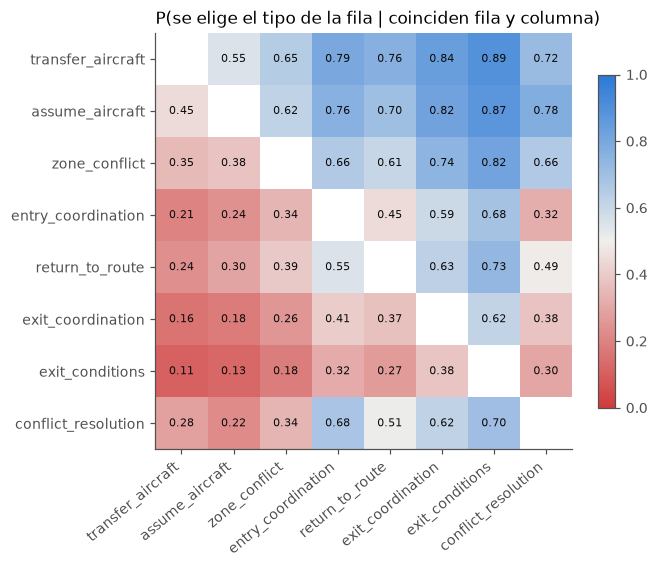

In [9]:
pres = labI.groupby("sample_id").task_index.apply(set)
ans = resp.task_index
T8 = [5, 4, 12, 2, 13, 3, 10, 6]
W = pd.DataFrame(np.nan, index=[TY[i] for i in T8], columns=[TY[i] for i in T8])
for x in T8:
    for y in T8:
        if x == y: continue
        m = pres.apply(lambda s: x in s and y in s) & ans.reindex(pres.index).isin([x, y])
        if m.sum() >= 30:
            W.loc[TY[x], TY[y]] = (ans.reindex(pres.index)[m] == x).mean()
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(W.values.astype(float), vmin=0, vmax=1,
               cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#d03b3b", "#f0efec", "#2a78d6"]))
ax.set_xticks(range(8), W.columns, rotation=40, ha="right"); ax.set_yticks(range(8), W.index); ax.grid(False)
for i in range(8):
    for j in range(8):
        v = W.values[i, j]
        if v == v: ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="#0b0b0b")
ax.set_title("P(se elige el tipo de la fila | coinciden fila y columna)", loc="left"); fig.colorbar(im, shrink=0.8)
plt.tight_layout(); plt.show()

**Lectura:** hay una jerarquía clara: transfer y assume ganan a casi todo; zone_conflict y return_to_route ganan a las coordinaciones;
entry_coordination solo gana a algunas tareas de salida. Es la prioridad aprendida del controlador "medio". Las excepciones (cuándo
gana la coordinación) son justo lo que el modelo no consigue ver.

### La señal principal, sin modelo: P(elegida) según los segundos hasta la siguiente instrucción

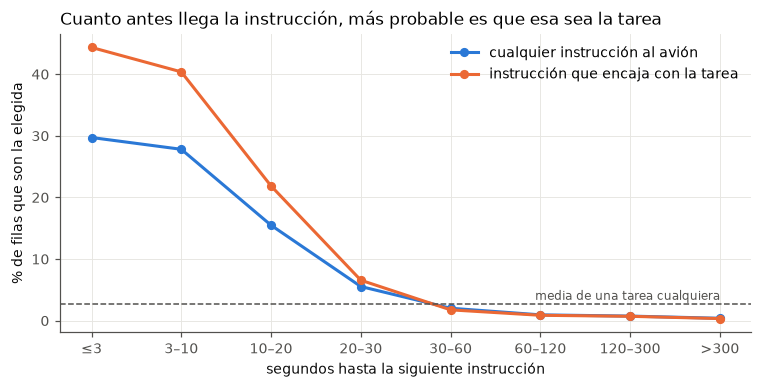

In [10]:
cortes = [-1, 3, 10, 20, 30, 60, 120, 300, 1e9]
et = ["≤3", "3–10", "10–20", "20–30", "30–60", "60–120", "120–300", ">300"]
fig, ax = plt.subplots(figsize=(7, 3.6))
for var, nombre, c in (("f_next_input", "cualquier instrucción al avión", CAT[0]), ("si_match", "instrucción que encaja con la tarea", CAT[1])):
    b = pd.cut(labI[var], cortes, labels=et)
    p = labI.target_index.groupby(b, observed=False).mean()
    ax.plot(range(len(et)), p.values * 100, marker="o", ms=5, lw=2, color=c, label=nombre)
base = labI.target_index.mean() * 100
ax.axhline(base, color=GRIS, lw=1, ls="--"); ax.text(len(et) - 1, base + 0.6, "media de una tarea cualquiera", ha="right", color=GRIS, fontsize=8)
ax.set_xticks(range(len(et)), et); ax.set_xlabel("segundos hasta la siguiente instrucción"); ax.set_ylabel("% de filas que son la elegida")
ax.set_title("Cuanto antes llega la instrucción, más probable es que esa sea la tarea", loc="left")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 2 · De dónde sale la nota: tres líneas y cuánta información aporta cada fuente

| Línea | Qué información usa | Dónde |
|---|---|---|
| **limpia** (`main`) | solo las filas del propio snapshot | `src/`, `notebooks/LGB_adri.ipynb`, `oof/` |
| **realista** | snapshot + snapshots **pasados** de la sesión | `realista/` |
| **futuro** | snapshot + pasado + **futuro** de la sesión (+ opcionalmente lo que hicieron otros controladores) | `futuro/` |

La tabla siguiente es la cadena completa, medida con los mismos folds.

In [11]:
CADENA = [
    ("limpia", "lgb_adri", "LightGBM LambdaRank, columnas originales + alerta + contexto"),
    ("limpia", "stack_meta", "meta-ranker sobre lgb_adri + red + tipos"),
    ("limpia", "lgb_adri_v2", "+ peso por tramo, 10 semillas (Adri) · público 0.642"),
    ("realista", "real_adri_noche_ses", "+ pasado: causal (cambios de estado recientes) + geo, búsqueda de parámetros (Pablo, Adri)"),
    ("futuro", "lgb_future", "+ futuro de la sesión: siguiente instrucción al avión, desaparición de la tarea · público 0.942"),
    ("futuro", "lgb_future_clear", "+ bloque clear: cuándo cambia el nivel, rumbo, zona o ruta del avión"),
    ("futuro", "lgb_future_clear_ses", "+ segundo paso de sesión: cada tarea se trabaja una sola vez"),
    ("futuro", "suav_lgb_future_clear10_ses", "A: 10 semillas + suavizado en la racha · público 0.947"),
    ("futuro", "f10_instr_l63_s10_ses", "N: + bloque instr (tipo de instrucción que encaja con la tarea) + 63 hojas + extra_trees · público 0.951"),
    ("futuro+oráculo", "suav_lgb_future_clear10_orcoord_ses", "B: A + oráculo de coordinaciones (otros controladores) · público 0.934"),
    ("futuro+oráculo", "f10_instr_l63_or_s10_ses", "NOR: N + oráculo de coordinaciones · público 0.948"),
    ("futuro+oráculo", "f11_M30_30", "M30_30: 0.7·C30 + 0.3·N30 en probabilidades, peso por CV anidada (Pablo, sección 24h) · público 0.953"),
]
T = pd.DataFrame([dict(linea=l, modelo=m, que=q, **medir(m)) for l, m, q in CADENA])
T

,linea,modelo,que,cv,peor_controlador,mediana_sesion,fuente
0,limpia,lgb_adri,"LightGBM LambdaRank, columnas originales + alerta + contexto",0.6562,0.571,0.6627,OOF
1,limpia,stack_meta,meta-ranker sobre lgb_adri + red + tipos,0.6600,0.580,0.6643,OOF
2,limpia,lgb_adri_v2,"+ peso por tramo, 10 semillas (Adri) · público 0.642",0.6644,0.579,0.6783,OOF
3,realista,real_adri_noche_ses,"+ pasado: causal (cambios de estado recientes) + geo, búsqueda de parámetros...",0.6722,0.595,0.6763,OOF
4,futuro,lgb_future,"+ futuro de la sesión: siguiente instrucción al avión, desaparición de la ta...",0.9010,0.769,0.9073,OOF
5,futuro,lgb_future_clear,"+ bloque clear: cuándo cambia el nivel, rumbo, zona o ruta del avión",0.9071,0.769,0.9189,OOF
6,futuro,lgb_future_clear_ses,+ segundo paso de sesión: cada tarea se trabaja una sola vez,0.9142,0.781,0.9248,OOF
7,futuro,suav_lgb_future_clear10_ses,A: 10 semillas + suavizado en la racha · público 0.947,0.9183,0.784,0.9292,OOF
8,futuro,f10_instr_l63_s10_ses,N: + bloque instr (tipo de instrucción que encaja con la tarea) + 63 hojas +...,0.9242,0.784,0.9292,OOF
9,futuro+oráculo,suav_lgb_future_clear10_orcoord_ses,B: A + oráculo de coordinaciones (otros controladores) · público 0.934,0.9259,0.796,0.9291,OOF


**Lectura:**
- **El pasado aporta ~1.5 puntos** (0.656 → 0.672). **El futuro aporta ~24** (0.672 → 0.90). Casi toda la nota sale de ver qué hace
  el controlador *después*: la siguiente instrucción que da al avión delata en qué estaba trabajando.
- Sobre el futuro, tres mejoras sólidas: `clear` (+0.6), el **segundo paso de sesión** (+0.7) y `instr` + árboles más grandes (+0.6).
- El **oráculo** (qué hicieron otros controladores del mismo escenario) suma +0.4–0.9 en CV, pero es la única fuente cuyo efecto
  varía mucho de un controlador a otro (sección 6).

### 2b · Cuánto azar hay: folds, semillas y reproducibilidad

Tres medidas: (1) cuánto varía la nota de un fold a otro con los folds fijos; (2) cuánto cambian la CV y las predicciones de test al
pasar de 3 a 10 y a 30 semillas del **mismo** modelo; (3) cuánto cambian al cambiar **de modelo**, para comparar. Más (4): NOR y
`f11_orc_s10` son la **misma configuración** (N + oráculo de coordinaciones, 10 semillas) entrenada por separado en dos máquinas.

In [12]:
def top3(df):
    df = df.sort_values(["sample_id", "score"], ascending=[True, False])
    return df.groupby("sample_id").row_index.apply(lambda r: frozenset(r.head(3)))

# (1) folds fijos: composición y CV de N por fold
fo = snap.join(hits(oof("f10_instr_l63_s10_ses")).rename("hit"))
F = fo.groupby("fold").agg(controladores=("atco", lambda a: " ".join(f"{x:03d}" for x in sorted(a.unique()))),
                           snapshots=("hit", "size"), sesiones=("session", "nunique"), CV_N=("hit", "mean"))
F["CV_N"] = F.CV_N.round(4)
print("Folds fijos (Data/folds.csv) y acierto de N en cada uno; desviación entre folds:", round(F.CV_N.std() * 100, 2), "puntos")
display(F)

# (2)–(4) mismas configuraciones con distinto nº de semillas, y cambios de modelo
VERS = [("N", "3 semillas", "f10_instr_l63_s3_ses"), ("N", "10 semillas", "f10_instr_l63_s10_ses"), ("N", "30 semillas", "f11_N30_ses"),
        ("N + oráculo", "3 semillas", "f10_instr_l63_or_s3_ses"), ("N + oráculo", "10 semillas (NOR)", "f10_instr_l63_or_s10_ses"),
        ("N + oráculo", "10 semillas, otra máquina", "f11_orc_s10_ses"), ("N + oráculo", "30 semillas (C30)", "f11_C30_ses")]
filas, T3, T3t = [], {}, {}
at_t = te.drop_duplicates("sample_id").set_index("sample_id").atco
for mod, sem, n in VERS:
    o, pr = oof(n), oof(n, "preds")
    if o is None:
        continue
    h = hits(o).rename("hit").to_frame().join(snap)
    T3[n], T3t[n] = top3(o), (top3(pr) if pr is not None else None)
    filas.append(dict(modelo=mod, semillas=sem, nombre=n, CV=round(h.hit.mean(), 4),
                      sd_entre_folds=round(h.groupby("fold").hit.mean().std() * 100, 2),
                      peor_controlador=round(h.groupby("atco").hit.mean().min(), 3)))
display(pd.DataFrame(filas))

def acuerdo(a, b, test=False):
    A, B = (T3t[a], T3t[b]) if test else (T3[a], T3[b])
    if A is None or B is None: return np.nan
    ids = A.index.intersection(B.index)
    if test: ids = ids[at_t.reindex(ids).values == 23]
    return round(100 * np.mean([A[i] == B[i] for i in ids]), 1)
PARES = [("azar: N 3 → 10 semillas", "f10_instr_l63_s3_ses", "f10_instr_l63_s10_ses"),
         ("azar: N 10 → 30 semillas", "f10_instr_l63_s10_ses", "f11_N30_ses"),
         ("azar: N+oráculo 3 → 10 semillas", "f10_instr_l63_or_s3_ses", "f10_instr_l63_or_s10_ses"),
         ("azar: N+oráculo 10 → 30 semillas", "f10_instr_l63_or_s10_ses", "f11_C30_ses"),
         ("reproducibilidad: NOR frente a la misma config. en otra máquina", "f10_instr_l63_or_s10_ses", "f11_orc_s10_ses"),
         ("modelo: N → N + oráculo (10 semillas)", "f10_instr_l63_s10_ses", "f10_instr_l63_or_s10_ses"),
         ("modelo: A → N", "suav_lgb_future_clear10_ses", "f10_instr_l63_s10_ses")]
for _, a, b in PARES[-1:]:
    for n in (a, b):
        if n not in T3 and oof(n) is not None:
            T3[n], T3t[n] = top3(oof(n)), top3(oof(n, "preds"))
Pt = pd.DataFrame([dict(comparacion=t, **{"top-3 igual en la CV (%)": acuerdo(a, b), "top-3 igual en el test 023 (%)": acuerdo(a, b, True)})
                   for t, a, b in PARES if a in T3 and b in T3])
display(Pt)

# ruido por controlador entre grupos de semillas
g = lambda n: hits(oof(n)).rename("h").to_frame().join(snap).groupby("atco").h.mean() * 100
d10_30 = g("f11_N30_ses") - g("f10_instr_l63_s10_ses")
print(f"N 10 → 30 semillas, cambio de acierto por controlador: media {d10_30.mean():+.2f}, desviación {d10_30.std():.2f} puntos, "
      f"máximo {d10_30.abs().max():.2f}")

Folds fijos (Data/folds.csv) y acierto de N en cada uno; desviación entre folds: 1.99 puntos


,controladores,snapshots,sesiones,CV_N
fold,,,,
0,007 014 018,2483,7,0.9573
1,001 003 004 015,2757,8,0.9071
2,002 006 009 016,2730,8,0.9114
3,008 017 019,2469,7,0.9202
4,005 010 011 020,2736,7,0.9276


,modelo,semillas,nombre,CV,sd_entre_folds,peor_controlador
0,N,3 semillas,f10_instr_l63_s3_ses,0.9233,1.99,0.784
1,N,10 semillas,f10_instr_l63_s10_ses,0.9242,1.99,0.784
2,N,30 semillas,f11_N30_ses,0.9234,1.99,0.781
3,N + oráculo,3 semillas,f10_instr_l63_or_s3_ses,0.9270,2.05,0.820
4,N + oráculo,10 semillas (NOR),f10_instr_l63_or_s10_ses,0.9278,2.12,0.802
5,N + oráculo,"10 semillas, otra máquina",f11_orc_s10_ses,0.9280,2.07,0.781
6,N + oráculo,30 semillas (C30),f11_C30_ses,0.9283,1.90,0.793


,comparacion,top-3 igual en la CV (%),top-3 igual en el test 023 (%)
0,azar: N 3 → 10 semillas,85.6,87.8
1,azar: N 10 → 30 semillas,91.5,93.8
2,azar: N+oráculo 3 → 10 semillas,85.8,87.4
3,azar: N+oráculo 10 → 30 semillas,88.0,89.1
4,reproducibilidad: NOR frente a la misma config. en otra máquina,85.6,86.1
5,modelo: N → N + oráculo (10 semillas),59.7,65.9
6,modelo: A → N,50.0,60.1


N 10 → 30 semillas, cambio de acierto por controlador: media -0.08, desviación 0.48 puntos, máximo 1.25


**Lectura:**
- **Folds:** con los folds fijos, la nota de N va de 0.907 (fold 1) a 0.957 (fold 0): ±2 puntos según qué controladores tocan. Es la
  misma incertidumbre que tendrá el privado, que es un controlador.
- **Semillas y CV:** la CV casi no se mueve con el número de semillas (N: 0.9233 / 0.9242 / 0.9234 con 3 / 10 / 30; N + oráculo:
  0.9270–0.9283). Por controlador, de 10 a 30 semillas el acierto cambia ±0.5 puntos (máximo 1.25): pequeño frente a la diferencia
  entre controladores.
- **El peor controlador sí es ruidoso:** con el oráculo va de 0.781 a 0.820 según el grupo de semillas. Conviene mirarlo, pero no
  decidir solo por él.
- **Semillas y predicciones:** de 3 a 10 semillas cambia el top-3 del ~13 % de los snapshots del 023; de 10 a 30, del ~6–11 %.
- **Modelo frente a azar:** cambiar de modelo mueve muchos más snapshots (N → N + oráculo: 34 % del 023; A → N: 40 %) que cambiar de
  semillas: las diferencias entre los modelos adoptados no son azar de semillas.
- **Reproducibilidad:** la misma configuración (N + oráculo, 10 semillas) entrenada por separado en otra máquina da la misma CV
  (0.9278 frente a 0.9280) y el mismo top-3 en el ~86 % de los snapshots, lo mismo que cambiar de grupo de semillas: se reproduce el
  resultado, no cada predicción exacta.

## 3 · Por qué funciona lo que funciona

### 3a · La regla que aprende el modelo: "el avión que recibe una instrucción en los próximos 10 s"

Contribución media (SHAP del primer pase) de cada origen de información y efecto de los segundos hasta la siguiente
instrucción al avión (`futuro/pruebas/f9_explica.py`). El reparto es el mismo en CV, en el test del 020 y en el del 023.

In [13]:
f9 = ROOT / "futuro/pruebas/notas/f9_influencia.csv"
pd.read_csv(f9, index_col=[0, 1]).round(1) if f9.exists() else "(falta notas/f9_influencia.csv)"

futuro  pasado  snapshot  futuro clear  otras sesiones
modelo zona                                                            
M0     CV          33.4     5.8      60.8           0.0             0.0
       test 020    34.1     5.0      61.0           0.0             0.0
       test 023    34.2     4.5      61.4           0.0             0.0
A      CV          29.6     5.3      55.6           9.5             0.0
       test 020    30.1     5.2      54.7          10.0             0.0
       test 023    30.5     4.8      55.9           8.8             0.0
O      CV          26.8     4.1      44.2           8.7            16.2
       test 020    27.9     4.0      43.7           9.3            15.2
       test 023    28.5     3.6      44.6           7.7            15.7
B      CV          27.5     4.6      50.2           8.6             9.1
       test 020    28.0     4.3      48.4           9.5             9.8
       test 023    28.2     4.0      50.2           8.7             8.9

| Siguiente instrucción al avión | ≤ 3 s | 3–10 s | 10–30 s | 30–60 s | > 60 s |
|---|---|---|---|---|---|
| efecto medio sobre el score (modelo A) | +2.0 | +1.9 | +0.9 | ≈ 0 | −0.1 |

### 3b · El segundo paso de sesión

Un logit condicional de 9 pesos (`futuro/feat_session.py`) sobre el score del primer pase en las otras rachas de la sesión. El peso
más grande es negativo: **si la tarea ya fue la favorita en otra racha, aquí probablemente no lo es** ("explaining away", porque cada
tarea se trabaja una vez). Debe ser pequeño: un LightGBM en su lugar sobreajusta (0.906 frente a 0.914). A la red la empeora.

### 3c · `instr` y árboles de 63 hojas con `extra_trees`

`f_next_input` solo mira la primera instrucción siguiente; en el 16 % de las filas la instrucción que encaja con la tarea
(nivel → exit_conditions, rumbo → return_to_route o zone, transfer → transfer) no es la primera. Ninguno de los dos cambios gana por
separado; juntos, +0.6. Cada paso se ha medido con 3 y con 10 semillas: el ruido entre semillas es de ±0.2.

## 4 · Dónde falla y dónde está el techo

In [14]:
def por_tipo(nombre):
    o = oof(nombre)
    if o is None: return None
    h = hits(o)
    return h.groupby(resp.task_index.reindex(h.index).map(lambda i: TY[i])).mean()
P = pd.DataFrame({k: por_tipo(v) for k, v in [("limpia", "lgb_adri"), ("A", "suav_lgb_future_clear10_ses"),
                                              ("N", "f10_instr_l63_s10_ses"), ("NOR", "f10_instr_l63_or_s10_ses")]})
P["% de respuestas"] = resp.task_index.map(lambda i: TY[i]).value_counts(normalize=True) * 100
P.sort_values("% de respuestas", ascending=False).round(3)

,limpia,A,N,NOR,% de respuestas
task_index,,,,,
transfer_aircraft,0.863,0.986,0.986,0.987,26.770
assume_aircraft,0.838,0.984,0.984,0.984,25.548
zone_conflict,0.707,0.934,0.945,0.955,16.099
entry_coordination,0.384,0.748,0.796,0.785,8.106
return_to_route,0.506,0.895,0.905,0.909,7.112
exit_coordination,0.093,0.632,0.631,0.648,5.655
exit_conditions,0.179,0.830,0.835,0.853,3.400
conflict_resolution,0.300,0.895,0.892,0.892,2.960
qos_improvement,0.163,0.934,0.914,0.934,1.951


In [15]:
# los fallos son de tramo entero: si el modelo falla un tramo, lo falla en todos sus snapshots
o = oof("f10_instr_l63_or_s10_ses")
h = hits(o).rename("hit").to_frame().join(snap).join(resp.task_name)
tr = h.groupby(["block", "task_name"]).hit.agg(["mean", "size"])
fallos = (1 - h.hit).sum()
pd.Series({
    "acierto (NOR)": f"{h.hit.mean():.4f}",
    "tramos acertados enteros": f"{(tr['mean'] == 1).mean():.1%}",
    "tramos fallados enteros": f"{(tr['mean'] == 0).mean():.1%}",
    "% de los fallos que están en tramos fallados enteros": f"{(tr.loc[tr['mean'] == 0, 'size'].sum() / fallos):.1%}",
}).to_frame("NOR")

,NOR
acierto (NOR),0.9278
tramos acertados enteros,93.5%
tramos fallados enteros,4.7%
% de los fallos que están en tramos fallados enteros,79.9%


**Lo que dicen los diagnósticos** (`futuro/pruebas/f8_diag.py`, `f8_parejas.py`, `errores.py`, `auditoria_coord.py`):
- **La mitad de los fallos son coordinaciones** (entry/exit). Coordinar con un sector vecino no es una instrucción al avión: no deja
  huella en las columnas. El 77 % de los tramos fallados no tiene ninguna huella observable ni en el pasado ni en el futuro.
- **El 41 % de los fallos acierta el avión pero no la tarea.** En las tareas de acción la respuesta desaparece a los ~3 s; en las
  coordinaciones la señal **se invierte** (desaparece la hermana, el transfer o el assume, y la coordinación sigue 1–3 min).
  Un clasificador dedicado a desempatar tareas del mismo avión no supera al modelo (92.1 % frente a 94.3 %).
- **Ante la misma situación, dos controladores eligen la misma tarea solo el 12.7 % de las veces.** No hay colisiones (features
  idénticas con etiquetas distintas): el error es reducible en teoría, pero la información que falta no está en los datos.
- **La curva de aprendizaje no se aplana** (25/50/75/100 % de los controladores: 0.870 / 0.893 / 0.898 / 0.906): más
  controladores ayudarían; el modelo final, entrenado con los 18, debería rendir algo por encima de la CV.

## 5 · Por qué no funciona lo que no funciona

Todas estas pruebas están medidas con la misma CV; el detalle y las cifras exactas están en la sección indicada de
`futuro/LGB_futuro.ipynb` (LF) o en el script.

| Familia | Pruebas | Resultado | Por qué |
|---|---|---|---|
| Otros modelos | XGBoost, CatBoost, red (transformer) con futuro | 0.896 / 0.874 / 0.887 frente a 0.901 (LF 5, 6c) | con la información del futuro todos aprenden lo mismo y fallan en los mismos snapshots |
| Stacks y mezclas sin oráculo | media ponderada, meta-ranker, stacks con sesión | ±0.1 (LF 6c, 13c, 15) | los modelos están muy correlacionados (0.86 de acuerdo); los pesos van a uno solo |
| Parámetros | lento, regularizado, más o menos hojas, truncation, objetivos binary/xendcg | ruido (LF 2–3, 12a; `f1_lgb.py`) | manda la información, no el ajuste; binary/xendcg empeoran tras el segundo paso |
| Bloques de features | `coord`, `block`, `rel`, `geo`, `logic` y `past` con futuro | 0 a −0.4 (LF 6, 11a, 16, 18, 19a) | lo que dicen ya está en `f_task_end` o en los rangos; no hay posiciones de aviones |
| Post-procesos en la racha | HMM, Kalman, modelo por racha, transiciones aprendidas, asignación de episodios | = suavizado o peor (LF 15, 23b) | los tramos se aciertan o se fallan enteros: no hay ningún snapshot bueno del que tirar |
| Variantes del segundo paso | Sinkhorn, LightGBM, más variables, iteraciones | saturado (LF 9, 11b) | el logit de 9 pesos ya recoge la estructura |
| Adaptación al controlador | prior por EM, covariate shift, Bayes jerárquico, estilo del controlador, pseudo-etiquetas | ruido o peor (LF 11c, 15, 18b, 21a, 23) | el estilo del controlador no es estable fuera de muestra; ajustarlo sin etiquetas refuerza los errores |
| Especialistas | solo coordinaciones, solo tareas con instrucción | peso óptimo 0 (LF 16, 23a) | no saben cuándo la respuesta NO es de su tipo |
| Etiquetas | relevancia graduada, quitar respuestas aisladas, limpiar etiquetas | ruido; limpiar era fuga (`f6_soft.py`; LGB_adri 12b) | el ruido de etiqueta no se arregla entrenando |
| Línea limpia | XGBoost, objetivos, selección de variables, dos etapas, red | ±0.007 (`pruebas/h1–h5`, `NN_pablo`) | con un solo snapshot el techo está en ~0.66: el 83 % de los fallos son del avión equivocado |

### 5b · Lo que no deja huella: ¿un modelo encima lo arregla?

En el ~41 % de los snapshots **ningún candidato tiene una instrucción compatible en ≤ 30 s** (se ve sin etiquetas, también en test).
Ahí el modelo con futuro se queda sin su pista principal y acierta ~0.88 frente a ~0.95. Idea: en esos snapshots, que decidan las
**prioridades** (plazos, cercanía al borde, antigüedad de la tarea), que es lo que aprendieron los modelos entrenados **sin futuro**
(la línea limpia `lgb_adri_v2` y la realista). Se mezcla solo en esos snapshots el log-softmax de la base con el del experto sin
futuro, con el peso elegido por CV anidada (`futuro/pruebas/f13_sinpista.py`).

Lo que ya se había intentado sobre estos casos: oráculo solo en filas sin huella propia y oráculo sin etiquetas (LF 24d), especialista
en coordinaciones (LF 16), clasificador dedicado a desempatar tareas del mismo avión (LF 20b) y vecinos más parecidos (kNN, LF 17).

In [16]:
import f13_sinpista
_ = f13_sinpista.main()

snapshots sin pista: 40.8%
                 base             experto  cv_base  cv_anidada                w_por_fold acierto_sin_pista controladores_suben_bajan  delta_cv023
f10_instr_l63_s10_ses         lgb_adri_v2   0.9242      0.9244 [0.1, 0.2, 0.1, 0.2, 0.1]    0.883 -> 0.886                     8 / 5         0.30
f10_instr_l63_s10_ses real_adri_noche_ses   0.9242      0.9239 [0.1, 0.1, 0.1, 0.2, 0.2]    0.883 -> 0.884                     5 / 9         0.23
           f11_M30_30         lgb_adri_v2   0.9290      0.9281 [0.1, 0.3, 0.1, 0.3, 0.1]    0.887 -> 0.888                     7 / 8         0.09
           f11_M30_30 real_adri_noche_ses   0.9290      0.9284 [0.1, 0.2, 0.1, 0.3, 0.2]    0.887 -> 0.888                     8 / 7         0.18


**Lectura:** la CV anidada siempre da muy poco peso al experto (0.1–0.3) y el resultado queda dentro del ruido entre semillas
(−0.09 a +0.02; controladores que suben y bajan casi empatados). Las prioridades ya están dentro del modelo principal y un experto en
ellas no añade nada. Junto con los intentos anteriores, cierra el hueco: cuando no hay huella, **ni el futuro, ni el pasado, ni las
prioridades, ni lo que hicieron otros controladores** distinguen la tarea correcta. Esa información no está en los datos
(comunicación no registrada con sectores vecinos, preferencia del controlador o ruido del etiquetado): para el modelo es azar.

## 6 · Público frente a privado y elección de las entregas

### 6a · El oráculo en el público

Kaggle solo enseña el público (controlador 020). Los primeros envíos con oráculo, sobre el modelo A, bajaron en el público aunque la
CV los daba por mejores (B 0.934, oráculo completo 0.940); sobre N ya no (NOR 0.948, M30_30 0.953).
Hipótesis H1 (formulada a posteriori con los 5 primeros envíos): cuantas más entry_coordination deja el modelo en el top-3 del 020,
mejor nota; el 020 coordina mucho y el oráculo saca entry_coordination del top-3. **Con los envíos siguientes deja de cumplirse:**
NOR y M30_30 dejan menos entry_coordination que A y que `lgb_future` y aun así sacan más; M30_30 (45 %) saca 0.953, la mejor nota
pública, cuando H1 le daba 0.945 (tabla de abajo). H1 era una pista débil, no una regla: el público son 2 sesiones y ±1–2 puntos de
ruido. El 023 casi no tiene entry_coordination como respuesta.

In [17]:
ENVIOS = {"lgb_future": ("futuro/submissions/sub_lgb_future.csv", 0.942),
          "A": ("futuro/submissions/sub_suav_lgb_future_clear10_ses.csv", 0.947),
          "oráculo completo": ("futuro/submissions/sub_suav_lgb_future_clear10_or_ses.csv", 0.940),
          "B": ("futuro/submissions/sub_suav_lgb_future_clear10_orcoord_ses.csv", 0.934),
          "N": ("futuro/pruebas/submissions/sub_f10_instr_l63_s10_ses.csv", 0.951),
          "NOR": ("futuro/pruebas/submissions/sub_f10_instr_l63_or_s10_ses.csv", 0.948),
          "M30_30": ("futuro/pruebas/submissions/sub_f11_M30_30.csv", 0.953)}
tipo = te.set_index(["sample_id", "row_index"]).task_index
at = te.drop_duplicates("sample_id").set_index("sample_id").atco
filas = []
for k, (f, pub) in ENVIOS.items():
    s = pd.read_csv(ROOT / f)
    top = s.assign(r=s.prediction.str.split()).explode("r").astype({"r": int})
    top["ec"] = [tipo.get((a, b)) == 2 for a, b in zip(top.sample_id, top.r)]
    g = top.groupby("sample_id").ec.any()
    filas.append(dict(envio=k, publico=pub, **{f"entry_coord en top-3 ({a:03d})": round(g[at.reindex(g.index) == a].mean() * 100, 1) for a in (20, 23)}))
pd.DataFrame(filas).sort_values("publico")

,envio,publico,entry_coord en top-3 (020),entry_coord en top-3 (023)
3,B,0.934,33.6,18.4
2,oráculo completo,0.940,36.7,22.7
0,lgb_future,0.942,44.0,25.6
1,A,0.947,47.7,26.9
5,NOR,0.948,41.6,22.6
4,N,0.951,54.0,26.4
6,M30_30,0.953,45.4,24.1


### 6b · Elegir la entrega por su privado esperado

Se elige una sola entrega y la clasificación final es **solo el privado** (controlador 023). El organizador ha avisado de un fuerte
sobreajuste al público en la competición: el público (2 sesiones del 020) no sirve para elegir. Todo se mide como diferencia frente a
**N**, la de mejor público. Cinco formas de estimar el privado, distintas entre sí (`futuro/pruebas/f13_eleccion.py`):

1. **Validar la regla de decisión.** Cada uno de los 18 controladores de la CV hace por turnos de "privado": se elige la candidata con
   mejor CV en los otros 17 y se mide su acierto en él. Responde: ¿el procedimiento "elegir por CV" acierta con un controlador nuevo?
2. **Riesgo a la baja.** Acierto por controlador de cada candidata: media de los 3 peores, peor controlador, y en qué fracción de
   controladores pierde más de 1 punto frente a N o le gana. El privado es *un* controlador: importa la cola, no solo la media.
3. **Cota por desacuerdo en test.** Dos entregas solo pueden sacar notas distintas en los snapshots en que su top-3 es distinto. Es un
   dato sin modelo: cuanto menos se aleja una candidata de N en el 023, menos puede ganar o perder frente a ella.
4. **CV reponderada hacia el 023.** Cada snapshot de la CV recibe un peso según cuánto se parece a los del 023 en variables que se ven
   sin etiquetas (si hay instrucción compatible en ≤ 30 s, si hay instrucción en ≤ 10 s, longitud de la lista, si el top-1 de N es una
   coordinación). Los pesos salen de una regresión logística que distingue CV frente a 023 (cociente de densidades); el *tamaño
   efectivo de muestra* dice cuánta información conserva la CV reponderada.
5. **Señal sin etiquetas validada.** Algo medible en el propio 023 sin etiquetas (estabilidad del top-1 dentro de la racha, repetición
   de la tarea favorita en otra racha). Solo vale si en la CV predice la diferencia de acierto entre modelos; si no, se descarta.

**Privado esperado:** media de los métodos 2 (media por controlador) y 4. La tabla incluye el público (real o estimado) solo como
referencia; no entra en la decisión.

In [18]:
sys.path.insert(0, str(ROOT / "futuro" / "pruebas"))
import f13_eleccion
tabla, info = f13_eleccion.main()

            cv  media_por_controlador  media_3_peores    peor  delta_vs_N_media  P(pierde >1 pt vs N)  P(gana vs N)  distinto_de_N_020  distinto_de_N_023  cv_reponderada_023  delta_reponderada_vs_N  estab_023_vs_N  repite_023_vs_N  publico      publico_fuente  delta_privado_esperado  delta_final_esperado
M30_30  92.896                 92.068          83.704  79.290             0.445                 0.000         0.556             28.197             21.941              94.056                   0.628           0.409            0.000    0.953                real                   0.537                 0.537
C30     92.835                 91.980          83.862  79.290             0.358                 0.056         0.889             39.672             31.224              94.073                   0.645           0.681            0.000    0.949  estimado desde NOR                   0.501                 0.501
NOR     92.782                 91.924          84.158  80.178             0.301   

**Lectura:**
- **Regla validada:** elegir por CV da M30_30 en 16 de 18 controladores y gana +0.22 a "quedarse siempre con N": el procedimiento
  funciona con controladores nuevos.
- **Riesgo:** M30_30 no pierde más de 1 punto frente a N en ningún controlador y su peor controlador está por encima del de N.
- **Desacuerdo:** M30_30 cambia el top-3 de N en el ~22 % de los snapshots del 023, menos que NOR o C30: es la opción con oráculo que
  menos se aleja de N.
- **Reponderada al 023:** las tres con oráculo ganan ~+0.6 a N; A pierde.
- **Señal sin etiquetas:** no predice el acierto en la CV (|r| ≤ 0.2): descartada.
- **Decisión por el privado esperado: M30_30** (+0.54 frente a N; C30 +0.50 y NOR +0.49 quedan muy cerca, dentro del ruido entre
  semillas). N tiene el mejor público, pero su privado esperado es el más bajo de las cuatro mejores.

### 6c · Lo que sabemos exactamente del 023

Del controlador 023 solo tenemos sus filas de test, **sin etiquetas**. Todo lo que sigue se mide sobre ellas (o compara con la CV).

In [19]:
from f10_instr import datos_instr
_, teI2, _ = datos_instr()
t23, lcv = teI2[teI2.atco == 23], labI
def resumen(d):
    g = d.groupby("sample_id")
    return pd.Series({"snapshots": d.sample_id.nunique(), "sesiones": d.session.nunique(),
                      "tareas por snapshot": round(g.size().mean(), 1),
                      "% snapshots con instrucción compatible ≤ 30 s": round(g.si_match.apply(lambda s: (s <= 30).any()).mean() * 100, 1),
                      "% snapshots con alguna instrucción ≤ 10 s": round(g.f_next_input.apply(lambda s: (s <= 10).any()).mean() * 100, 1),
                      "instrucciones en los últimos 5 min (a_n300)": round(d.drop_duplicates("sample_id").a_n300.mean(), 1)})
Q = pd.DataFrame({"CV (18 controladores)": resumen(lcv), "023 (test)": resumen(t23)})
for ses, g in t23.groupby("session"):
    Q[ses] = resumen(g)
Q

,CV (18 controladores),023 (test),023sc1,023sc2,023sc3
snapshots,13175.0,948.0,276.0,344.0,328.0
sesiones,37.0,3.0,1.0,1.0,1.0
tareas por snapshot,36.0,31.0,27.7,30.6,34.1
% snapshots con instrucción compatible ≤ 30 s,59.2,54.9,44.6,54.1,64.3
% snapshots con alguna instrucción ≤ 10 s,40.8,36.4,29.0,34.9,44.2
instrucciones en los últimos 5 min (a_n300),17.8,16.4,14.0,16.3,18.4


Y de los análisis de las secciones 20–24 de `LGB_futuro.ipynb`:
- **Coordina poco:** el top-1 de los modelos es una coordinación en el 3–4 % de sus snapshots (~10 % en la CV) y una entry_coordination
  en el 0.1 %. Es lo contrario del 020, que coordina mucho: lo que castigó al oráculo en el público pesa poco en el 023.
- **Es atípico:** 023sc2 es la sesión de estilo más extrema de todas (percentil 100; muchos assume forzados); 023sc1 se parece al 001,
  el peor controlador de la CV. Tiene listas más cortas, menos ritmo y más conflict_resolution en 023sc2 (9 % frente al 2 %).
- **Más difícil:** los modelos están menos seguros en él y tiene menos snapshots con instrucción inminente: se espera un privado de
  ~0.91–0.92 (±5), unos 3 puntos por debajo del público, sea cual sea la entrega.
- **Controladores de la CV más parecidos:** 002, 011, 010, 006, 017, 015 ("CV 023"); en ellos M30_30 da 0.934 frente a 0.929 de N.

**Decisión: `futuro/pruebas/submissions/sub_f11_M30_30.csv`.** Es la de mejor privado esperado con los cinco métodos de 6b, la que
elige la regla "por CV" en 16 de 18 controladores, no pierde más de 1 punto frente a N en ninguno y es la opción con oráculo que menos
se aleja de N en el 023. **Público: 0.953**, la mejor nota pública del equipo (N 0.951, NOR 0.948). Se había estimado 0.946–0.951:
el método que más se acercó fue la CV frente a NOR (0.951); H1 (0.945) volvió a fallar. El público no decidía, pero confirma que el
fichero está bien y que el oráculo mezclado con N también funciona en un controlador que coordina mucho.

**Reglas:** el organizador confirmó (21/10, 03:15) que se puede usar cualquier información de los datasets (snapshots futuros y
pasados, etiquetas de otras sesiones). La entrega limpia de referencia, solo con el propio snapshot, es
`submissions/sub_lgb_adri_v2.csv` (CV 0.664, público 0.642).

## 7 · Reproducir los envíos

```bash
# A y B (Pablo): LightGBM con futuro + clear, 10 semillas, + segundo paso de sesión (+ oráculo de coordinaciones para B)
python futuro/m_lgb_future.py --feats base,logic,past,future,clear --sesion --seeds 10 --name lgb_future_clear10
python futuro/m_lgb_future.py --feats base,logic,past,future,clear --sesion --oraculo --oraculo-var coord --seeds 10 --name lgb_future_clear10_orcoord
python futuro/pruebas/f5_stack.py suav lgb_future_clear10_ses lgb_future_clear10_orcoord_ses     # suavizado con CV anidada
# N y NOR (Juanma): + bloque instr, 63 hojas, extra_trees, 10 semillas, + sesión (+ oráculo para NOR)
bash futuro/pruebas/f10_final.sh                          # N
python futuro/pruebas/f10_instr.py cv f10_instr_l63_or 10 # NOR
# M30_30 (Pablo): C30 y N30 con futuro/pruebas/f11_lab.py y mezcla 0.7·C30 + 0.3·N30 con f11_mezcla.py (LGB_futuro.ipynb, 24h-24n)
# comparar dos OOF con el criterio robusto (media, mediana por sesión, controladores, bootstrap, escenarios)
python futuro/pruebas/comparar.py suav_lgb_future_clear10_ses f10_instr_l63_or_s10_ses
```
Las salidas de experimentos que no alimentan ningún envío se movieron fuera del repo (`~/FlowDataLab_archivo/`); sus cifras siguen en
`futuro/pruebas/resultados.jsonl` y en `experiments/*.csv`.